Nama : Candra Sya'bana Putra Gunadi<br>
NIM  : 60324042 <br>
Kelas: Visualisasi Data A <br>

# Praktikum

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)
df = df.dropna(subset=["embarked"])
df["kelas"] = df["pclass"].map({1: "Kelas 1", 2: "Kelas 2", 3: "Kelas 3"})
df["gender"] = df["sex"].map({"female": "Perempuan", "male": "Laki-laki"})
df["status"] = df["survived"].map({0: "Tidak selamat", 1: "Selamat"})
sns.set_theme(style="whitegrid")
print("Data siap divisualisasikan:", df.shape)

Data siap divisualisasikan: (889, 18)


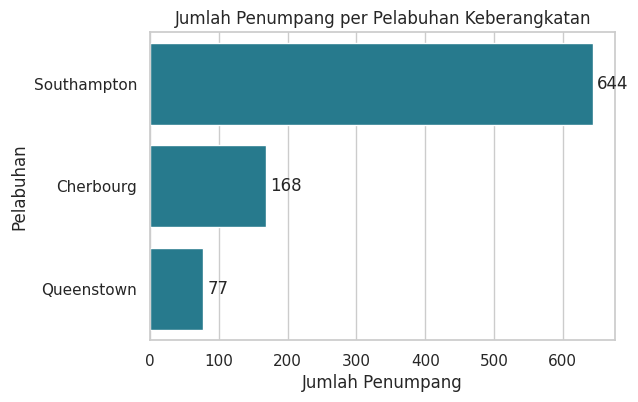

In [ ]:
urutan = df["embark_town"].value_counts().index

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, y="embark_town", order=urutan,
color="#16849E", ax=ax)

ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Jumlah Penumpang per Pelabuhan Keberangkatan")
ax.set_xlabel("Jumlah Penumpang")
ax.set_ylabel("Pelabuhan")
plt.show()

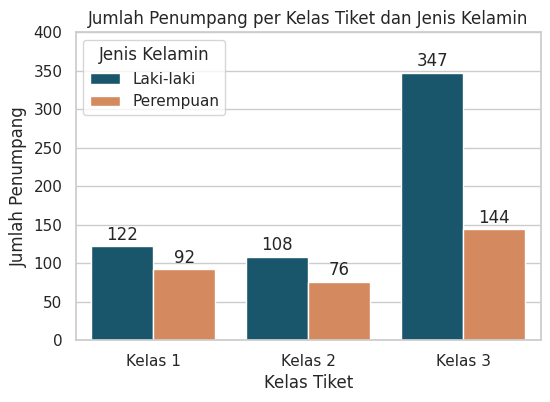

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="kelas", hue="gender",
              order=["Kelas 1", "Kelas 2", "Kelas 3"],
              palette={"Perempuan": "#E8834A", "Laki-laki": "#0B5D7A"},
ax=ax)

for wadah in ax.containers:
  ax.bar_label(wadah, padding=2)
ax.set_ylim(0, 400)
ax.set_title("Jumlah Penumpang per Kelas Tiket dan Jenis Kelamin")
ax.set_xlabel("Kelas Tiket")
ax.set_ylabel("Jumlah Penumpang")
ax.legend(title="Jenis Kelamin")
plt.show()

     kelas     gender  persen_selamat
0  Kelas 1  Laki-laki            36.9
1  Kelas 1  Perempuan            96.7
2  Kelas 2  Laki-laki            15.7
3  Kelas 2  Perempuan            92.1
4  Kelas 3  Laki-laki            13.5
5  Kelas 3  Perempuan            50.0


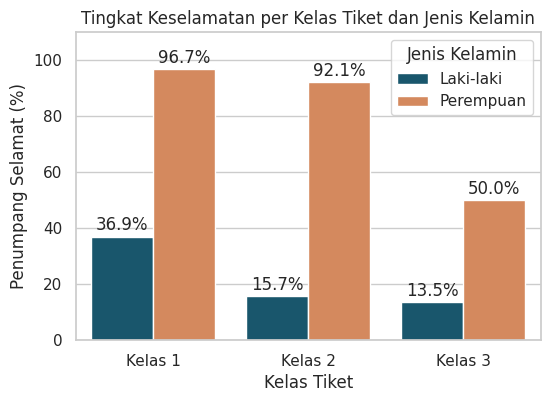

In [ ]:
tingkat = (df.groupby(["kelas", "gender"])["survived"].mean() *
100).round(1)
tingkat = tingkat.reset_index(name="persen_selamat")
print(tingkat)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=tingkat, x="kelas", y="persen_selamat", hue="gender",
            palette={"Perempuan": "#E8834A", "Laki-laki": "#0B5D7A"}, ax=ax)

for wadah in ax.containers:
  ax.bar_label(wadah, fmt="%.1f%%", padding=2)
ax.set_ylim(0, 110)
ax.set_title("Tingkat Keselamatan per Kelas Tiket dan Jenis Kelamin")
ax.set_xlabel("Kelas Tiket")
ax.set_ylabel("Penumpang Selamat (%)")
ax.legend(title="Jenis Kelamin")
plt.show()

status   Selamat  Tidak selamat
kelas                          
Kelas 1      134             80
Kelas 2       87             97
Kelas 3      119            372


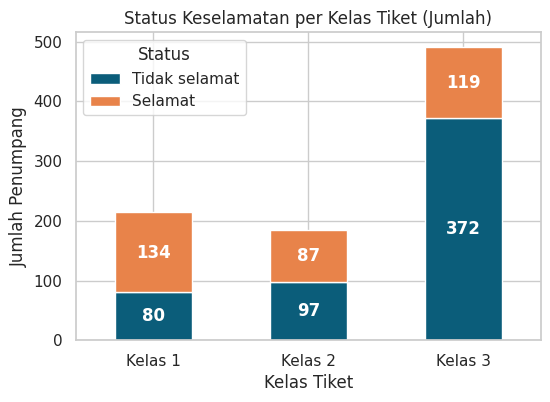

In [ ]:
tabel = pd.crosstab(df["kelas"], df["status"])
print(tabel)
fig, ax = plt.subplots(figsize=(6, 4))
tabel[["Tidak selamat", "Selamat"]].plot(
    kind="bar", stacked=True, rot=0,
    color=["#0B5D7A", "#E8834A"], ax=ax)

for wadah in ax.containers:
  ax.bar_label(wadah, label_type="center", color="white",
fontweight="bold")
ax.set_title("Status Keselamatan per Kelas Tiket (Jumlah)")
ax.set_xlabel("Kelas Tiket")
ax.set_ylabel("Jumlah Penumpang")
ax.legend(title="Status")
plt.show()

status   Selamat  Tidak selamat
kelas                          
Kelas 1     62.6           37.4
Kelas 2     47.3           52.7
Kelas 3     24.2           75.8


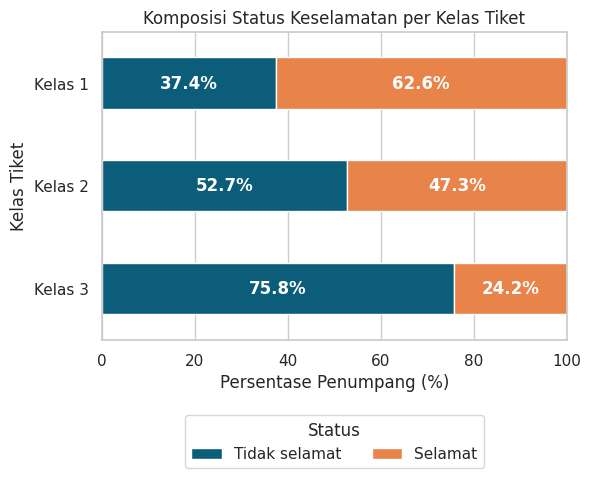

In [ ]:
proporsi = pd.crosstab(df["kelas"], df["status"], normalize="index") * 100
print(proporsi.round(1))

fig, ax = plt.subplots(figsize=(6, 4))
proporsi[["Tidak selamat", "Selamat"]].plot(
  kind="barh", stacked=True,
  color=["#0B5D7A", "#E8834A"], ax=ax)

for wadah in ax.containers:
  ax.bar_label(wadah, fmt="%.1f%%", label_type="center",
color="white", fontweight="bold")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_title("Komposisi Status Keselamatan per Kelas Tiket")
ax.set_xlabel("Persentase Penumpang (%)")
ax.set_ylabel("Kelas Tiket")
ax.legend(title="Status", loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.show()

In [ ]:
!pip install squarify -q

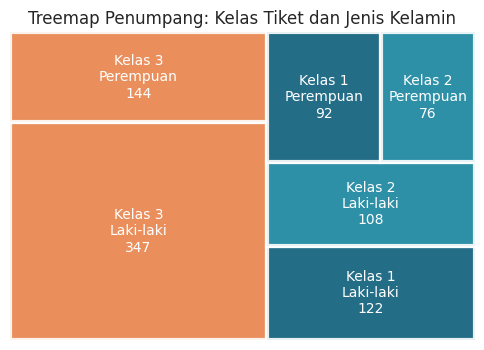

In [ ]:
import squarify

ukuran = df.groupby(["kelas", "gender"]).size().reset_index(name="jumlah")
ukuran = ukuran.sort_values("jumlah", ascending=False)

label = [f"{k}\n{g}\n{n}" for k, g, n in
        zip(ukuran["kelas"], ukuran["gender"], ukuran["jumlah"])]

warna = ukuran["kelas"].map({"Kelas 1": "#0B5D7A",
                              "Kelas 2": "#16849E",
                              "Kelas 3": "#E8834A"})

fig, ax = plt.subplots(figsize=(6, 4))
squarify.plot(sizes=ukuran["jumlah"], label=label, color=warna, alpha=0.9,
              bar_kwargs={"edgecolor": "white", "linewidth": 3},
              text_kwargs={"color": "white", "fontsize": 10}, ax=ax)
ax.set_title("Treemap Penumpang: Kelas Tiket dan Jenis Kelamin")
ax.axis("off")
plt.show()

In [ ]:
# Menghitung data pendukung untuk Jawaban Proyek Mini

# Pertanyaan 1: Kelas tiket terbanyak dan persentasenya
kelas_counts = df['kelas'].value_counts()
kelas_pct = df['kelas'].value_counts(normalize=True) * 100
print("PERTANYAAN 1")
for k in kelas_counts.index:
    print(f"{k}: jumlah = {kelas_counts[k]}, persentase = {kelas_pct[k]:.1f}%")

# Pertanyaan 2: Selisih tingkat keselamatan perempuan dan laki-laki di ketiga kelas
tingkat_selamat = df.groupby(['kelas', 'gender'])['survived'].mean() * 100
print("\n PERTANYAAN 2 ")
for k in ['Kelas 1', 'Kelas 2', 'Kelas 3']:
    p_selamat = tingkat_selamat[(k, 'Perempuan')]
    l_selamat = tingkat_selamat[(k, 'Laki-laki')]
    selisih = p_selamat - l_selamat
    print(f"{k} -> Perempuan: {p_selamat:.1f}%, Laki-laki: {l_selamat:.1f}%, Selisih: {selisih:.1f} poin persentase")

# Pertanyaan 3: Dominasi Kelas 3 berdasarkan Pelabuhan
pelabuhan_kelas = pd.crosstab(df['embark_town'], df['kelas'], normalize='index') * 100
print("\n PERTANYAAN 3")
print(pelabuhan_kelas.round(1))

PERTANYAAN 1
Kelas 3: jumlah = 491, persentase = 55.2%
Kelas 1: jumlah = 214, persentase = 24.1%
Kelas 2: jumlah = 184, persentase = 20.7%

 PERTANYAAN 2 
Kelas 1 -> Perempuan: 96.7%, Laki-laki: 36.9%, Selisih: 59.9 poin persentase
Kelas 2 -> Perempuan: 92.1%, Laki-laki: 15.7%, Selisih: 76.4 poin persentase
Kelas 3 -> Perempuan: 50.0%, Laki-laki: 13.5%, Selisih: 36.5 poin persentase

 PERTANYAAN 3
kelas        Kelas 1  Kelas 2  Kelas 3
embark_town                           
Cherbourg       50.6     10.1     39.3
Queenstown       2.6      3.9     93.5
Southampton     19.7     25.5     54.8


Notebook ini merangkum proses eksplorasi dan pembuatan visualisasi data dari dataset Titanic melalui tahapan-tahapan berikut:

1. **Tahap Pra-pemrosesan Data**
   * Mengimpor dataset Titanic langsung dari repositori GitHub Seaborn.
   * Membersihkan data dengan menghapus nilai kosong pada kolom pelabuhan asal (`embarked`).
   * Mengubah nilai pada variabel kelas tiket, jenis kelamin, dan status keselamatan ke dalam bahasa Indonesia agar lebih mudah dipahami (proses pemetaan/ *mapping*).

2. **Hasil Visualisasi Data**
   * **Bar Chart Dasar**: Menggambarkan bahwa Southampton adalah pelabuhan keberangkatan tersibuk dengan total 644 penumpang.
   * **Grouped Count Plot**: Memperlihatkan sebaran jumlah penumpang berdasarkan interaksi antara kelas tiket dan gender.
   * **Grouped Bar Chart (Persentase)**: Menyoroti pola keselamatan, di mana probabilitas keselamatan perempuan jauh mengungguli laki-laki pada semua kelas.
   * **Stacked Bar Chart**: Menyajikan perbandingan angka pasti (absolut) antara penumpang yang selamat dan yang tidak pada setiap kelas.
   * **100% Stacked Bar Chart**: Menampilkan rasio proporsi keselamatan yang memperlihatkan bahwa Kelas 1 memiliki persentase selamat tertinggi, berbanding terbalik dengan kondisi di Kelas 3.
   * **Treemap**: Menggambarkan komposisi proporsi penumpang berdasarkan kelas dan jenis kelamin dalam bentuk area visual.

3. **Kesimpulan Proyek Mini**
   * **Pertanyaan 1**: Mayoritas penumpang kapal berada di Kelas 3, dengan total 491 orang (mencakup 55,2% dari keseluruhan).
   * **Pertanyaan 2**: Perempuan konsisten memiliki tingkat keselamatan yang lebih tinggi. Kesenjangan keselamatan terkecil antara laki-laki dan perempuan ada di Kelas 3 (36,5 poin), sedangkan kesenjangan paling ekstrem ada di Kelas 2 (76,4 poin).
   * **Pertanyaan 3**: Karakteristik Pelabuhan Queenstown sangat unik karena 93,5% dari total penumpang yang berangkat dari pelabuhan tersebut merupakan penumpang Kelas 3.

# Latihan Mandiri

Latihan 1

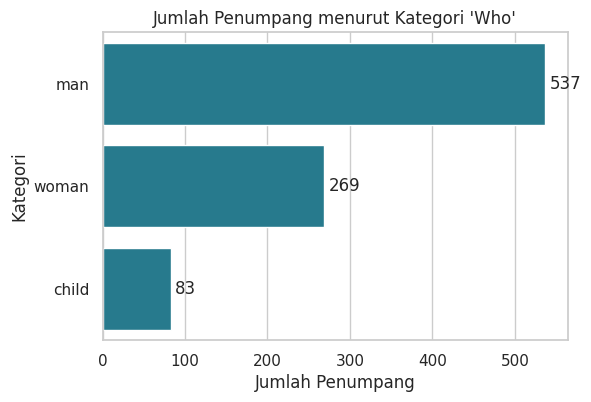

who
man      537
woman    269
child     83
Name: count, dtype: int64


In [ ]:
urutan_who = df["who"].value_counts().index

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, y="who", order=urutan_who, color="#16849E", ax=ax)

ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Jumlah Penumpang menurut Kategori 'Who'")
ax.set_xlabel("Jumlah Penumpang")
ax.set_ylabel("Kategori")
plt.show()

# Menampilkan nilai persis untuk analisis
print(df["who"].value_counts())

Latihan 2

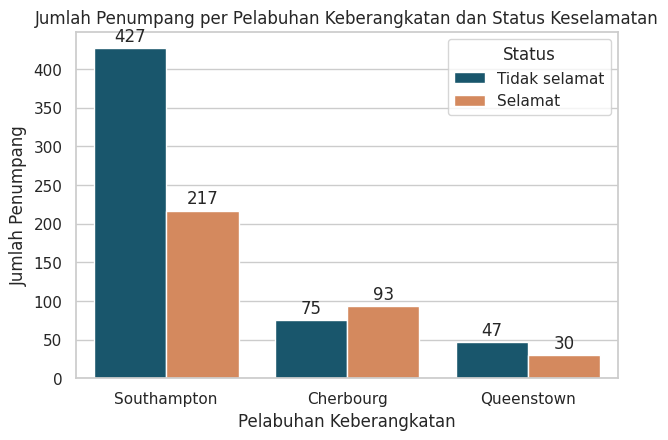

Persentase Selamat per Pelabuhan Keberangkatan:
embark_town
Cherbourg      55.4
Queenstown     39.0
Southampton    33.7
Name: survived, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="embark_town", hue="status", palette={"Selamat": "#E8834A", "Tidak selamat": "#0B5D7A"}, ax=ax)

for wadah in ax.containers:
    ax.bar_label(wadah, padding=2)

ax.set_title("Jumlah Penumpang per Pelabuhan Keberangkatan dan Status Keselamatan")
ax.set_xlabel("Pelabuhan Keberangkatan")
ax.set_ylabel("Jumlah Penumpang")
ax.legend(title="Status")
plt.show()

# Menghitung persentase selamat
persentase_pelabuhan = (df.groupby("embark_town")["survived"].mean() * 100).round(1)
print("Persentase Selamat per Pelabuhan Keberangkatan:")
print(persentase_pelabuhan)

Latihan 3

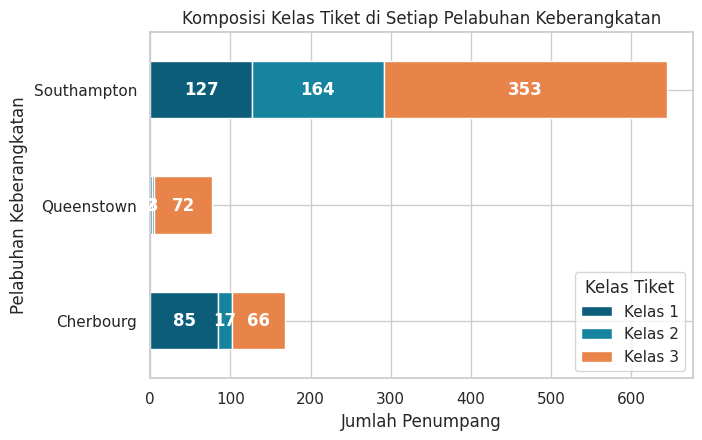

In [ ]:
crosstab_pelabuhan_kelas = pd.crosstab(df["embark_town"], df["kelas"])

fig, ax = plt.subplots(figsize=(7, 4.5))
crosstab_pelabuhan_kelas.plot(kind="barh", stacked=True, color=["#0B5D7A", "#16849E", "#E8834A"], ax=ax)

for wadah in ax.containers:
    ax.bar_label(wadah, label_type="center", color="white", fontweight="bold")

ax.set_title("Komposisi Kelas Tiket di Setiap Pelabuhan Keberangkatan")
ax.set_xlabel("Jumlah Penumpang")
ax.set_ylabel("Pelabuhan Keberangkatan")
ax.legend(title="Kelas Tiket")
plt.show()

Latihan 4

status             Selamat  Tidak selamat
kelas   gender                           
Kelas 1 Laki-laki     36.9           63.1
        Perempuan     96.7            3.3
Kelas 2 Laki-laki     15.7           84.3
        Perempuan     92.1            7.9
Kelas 3 Laki-laki     13.5           86.5
        Perempuan     50.0           50.0


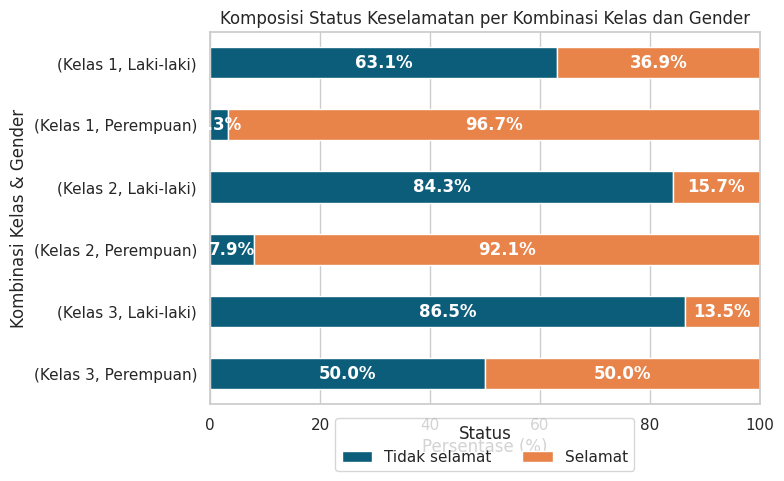

In [ ]:
crosstab_kelas_gender_status = pd.crosstab([df["kelas"], df["gender"]], df["status"], normalize="index") * 100
print(crosstab_kelas_gender_status.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
crosstab_kelas_gender_status[["Tidak selamat", "Selamat"]].plot(
    kind="barh", stacked=True, color=["#0B5D7A", "#E8834A"], ax=ax
)

for wadah in ax.containers:
    ax.bar_label(wadah, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_title("Komposisi Status Keselamatan per Kombinasi Kelas dan Gender")
ax.set_xlabel("Persentase (%)")
ax.set_ylabel("Kombinasi Kelas & Gender")
ax.legend(title="Status", loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

Latihan 5

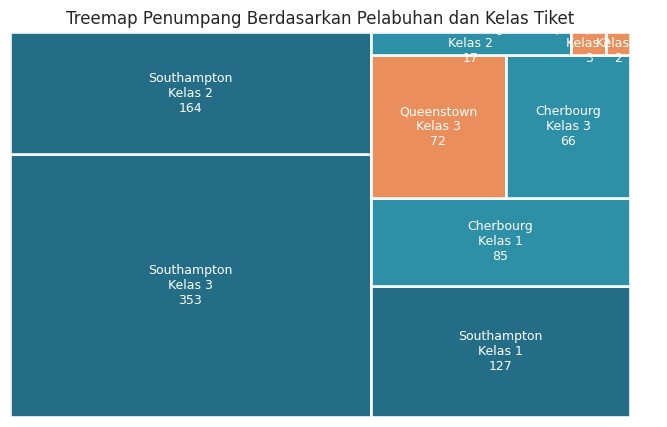

In [ ]:
import squarify

df_ringkas = df.groupby(["embark_town", "kelas"]).size().reset_index(name="jumlah")
df_ringkas = df_ringkas.sort_values("jumlah", ascending=False)

label_latih5 = [f"{p}\n{k}\n{j}" for p, k, j in
                zip(df_ringkas["embark_town"], df_ringkas["kelas"], df_ringkas["jumlah"])]

# Menyiapkan warna berdasarkan pelabuhan
warna_latih5 = df_ringkas["embark_town"].map({"Southampton": "#0B5D7A", "Cherbourg": "#16849E", "Queenstown": "#E8834A"})

fig, ax = plt.subplots(figsize=(8, 5))
squarify.plot(sizes=df_ringkas["jumlah"], label=label_latih5, color=warna_latih5, alpha=0.9,
              bar_kwargs={"edgecolor": "white", "linewidth": 2},
              text_kwargs={"color": "white", "fontsize": 9}, ax=ax)
ax.set_title("Treemap Penumpang Berdasarkan Pelabuhan dan Kelas Tiket")
ax.axis("off")
plt.show()

# Bonus: Treemap Interaktif dengan Plotly
import plotly.express as px
fig_plotly = px.treemap(df_ringkas, path=["embark_town", "kelas"], values="jumlah",
                        title="Treemap Interaktif Penumpang Berdasarkan Pelabuhan dan Kelas Tiket")
fig_plotly.show()

# Pertanyaan Diskusi

1. **Perbandingan Grafik Angka Absolut vs Grafik Persentase**
   * **Alasan Perbedaan Visual:** Grafik jumlah (absolut) sangat dipengaruhi oleh ketimpangan ukuran populasi tiap kelompok (misalnya, total penumpang Kelas 3 jauh melampaui Kelas 1). Sebaliknya, grafik persentase menetralkan ketimpangan tersebut sehingga kita dapat melihat rasio atau peluang (seperti keselamatan) secara lebih proporsional dan adil.
   * **Kapan Harus Digunakan:**
     * **Angka Absolut:** Sangat ideal ketika besaran riil atau volume pasti sangat dibutuhkan (contoh: menghitung kebutuhan logistik atau kapasitas sekoci).
     * **Persentase:** Lebih tepat digunakan untuk membandingkan probabilitas, efektivitas, atau tren performa antar kelompok yang memiliki total sampel berbeda drastis.

2. **Kriteria Pemilihan Grouped Bar, Stacked Bar, dan 100% Stacked Bar**
   * **Grouped Bar (Batang Berkelompok):** Paling cocok untuk membandingkan nilai-nilai spesifik dari setiap sub-kategori secara presisi dan berdampingan (contoh: perbandingan rata-rata gaji pria dan wanita di beberapa program studi).
   * **Stacked Bar (Batang Bertumpuk):** Sangat berguna jika Anda ingin menonjolkan akumulasi total nilai sekaligus melihat porsi kontribusi nominal masing-masing komponen di dalamnya (contoh: visualisasi total penjualan bulanan yang dirinci berdasarkan kategori produk).
   * **100% Stacked Bar (Batang Bertumpuk 100%):** Dipilih saat tujuan utamanya adalah melihat rasio atau persentase relatif setiap bagian dalam suatu kelompok, tanpa mempedulikan perbedaan jumlah total aslinya (contoh: membandingkan rasio kepuasan pelanggan di berbagai cabang).

3. **Keunggulan dan Kelemahan Treemap Dibandingkan Bar Chart**
   * **Keunggulan Treemap:** Sangat efektif dan secara visual menarik untuk menampilkan data yang berstruktur hierarki maupun komposisi *part-to-whole* (bagian dari keseluruhan). Grafik ini juga efisien dalam memanfaatkan ruang layar, bahkan ketika ada puluhan kategori.
   * **Kelemahan Treemap:** Kurang presisi karena mata manusia lebih sulit membedakan perbedaan ukuran luas area kotak dibandingkan mengukur tinggi batang pada *bar chart*. Selain itu, kategori dengan jumlah sangat kecil seringkali sulit terbaca karena keterbatasan ruang untuk teks label.